<a href="https://colab.research.google.com/github/SRXKaiser/analitica-de-datos/blob/main/Practicas%20U3/Practias_Finales_de_Equipo/Arbol_de_desicion_Practica_de_Equipo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ANÁLISIS Y PREDICCIÓN DE LA POPULARIDAD DE CANCIONES EN SPOTIFY

**Practica de Equipo 3:**  Arbol de desicion

**Número de control:**

- Víctor Manuel Landeros Ramírez - 2311

- Karely Pérez Vargas – 23111441

- Diego Pulido Hernández – 22111487




**Materia:** Analítica de Datos

**Importar las bibliotecas**

In [43]:
# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Preparación de datos
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Modelos
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

# Métricas de regresión
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Métricas de clasificación
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Modelos de referencia
from sklearn.dummy import DummyRegressor, DummyClassifier

# Configuración de gráficas
sns.set_theme(style="whitegrid")

print("Bibliotecas importadas correctamente")

Bibliotecas importadas correctamente


In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Cargar el dataset**

In [11]:

df = pd.read_csv("/content/spotify_data clean.csv")

df.head()

,track_id,track_name,track_number,track_popularity,explicit,artist_name,artist_popularity,artist_followers,artist_genres,album_id,album_name,album_release_date,album_total_tracks,album_type,track_duration_min
0,3EJS5LyekDim1Tf5rBFmZl,Trippy Mane (ft. Project Pat),4,0,True,Diplo,77,2812821,moombahton,5QRFnGnBeMGePBKF2xTz5z,"d00mscrvll, Vol. 1",2025-10-31,9,album,1.55
1,1oQW6G2ZiwMuHqlPpP27DB,OMG!,1,0,True,Yelawolf,64,2363438,"country hip hop, southern hip hop",4SUmmwnv0xTjRcLdjczGg2,OMG!,2025-10-31,1,single,3.07
2,7mdkjzoIYlf1rx9EtBpGmU,Hard 2 Find,1,4,True,Riff Raff,48,193302,NaN,3E3zEAL8gUYWaLYB9L7gbp,Hard 2 Find,2025-10-31,1,single,2.55
3,67rW0Zl7oB3qEpD5YWWE5w,Still Get Like That (ft. Project Pat & Starrah),8,30,True,Diplo,77,2813710,moombahton,5QRFnGnBeMGePBKF2xTz5z,"d00mscrvll, Vol. 1",2025-10-31,9,album,1.69
4,15xptTfRBrjsppW0INUZjf,ride me like a harley,2,0,True,Rumelis,48,8682,dark r&b,06FDIpSHYmZAZoyuYtc7kd,come closer / ride me like a harley,2025-10-30,2,single,2.39


**Exploración de los datos**

In [12]:
#Cantidad de filas y columnas
print("Dimensiones del dataset:")
print(df.shape)

print("\nColumnas del dataset:")
print(df.columns.tolist())

Dimensiones del dataset:
(8582, 15)

Columnas del dataset:
['track_id', 'track_name', 'track_number', 'track_popularity', 'explicit', 'artist_name', 'artist_popularity', 'artist_followers', 'artist_genres', 'album_id', 'album_name', 'album_release_date', 'album_total_tracks', 'album_type', 'track_duration_min']


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8582 entries, 0 to 8581
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   track_id            8582 non-null   object 
 1   track_name          8582 non-null   object 
 2   track_number        8582 non-null   int64  
 3   track_popularity    8582 non-null   int64  
 4   explicit            8582 non-null   bool   
 5   artist_name         8579 non-null   object 
 6   artist_popularity   8582 non-null   int64  
 7   artist_followers    8582 non-null   int64  
 8   artist_genres       5221 non-null   object 
 9   album_id            8582 non-null   object 
 10  album_name          8582 non-null   object 
 11  album_release_date  8582 non-null   object 
 12  album_total_tracks  8582 non-null   int64  
 13  album_type          8582 non-null   object 
 14  track_duration_min  8582 non-null   float64
dtypes: bool(1), float64(1), int64(5), object(8)
memory usag

Valores faltantes

In [14]:
print("Valores faltantes por columna:")
print(df.isnull().sum())

Valores faltantes por columna:
track_id                 0
track_name               0
track_number             0
track_popularity         0
explicit                 0
artist_name              3
artist_popularity        0
artist_followers         0
artist_genres         3361
album_id                 0
album_name               0
album_release_date       0
album_total_tracks       0
album_type               0
track_duration_min       0
dtype: int64


Registros duplicados

In [15]:
print("Registros duplicados:")
print(df.duplicated().sum())

Registros duplicados:
0


Estadísticas descriptivas

In [16]:
df.describe()

,track_number,track_popularity,artist_popularity,artist_followers,album_total_tracks,track_duration_min
count,8582.000000,8582.000000,8582.000000,8.582000e+03,8582.000000,8582.000000
mean,5.772547,52.356211,69.730016,2.403472e+07,13.789443,3.492805
std,6.052792,23.816076,19.645979,3.803180e+07,11.887131,1.057970
min,1.000000,0.000000,0.000000,0.000000e+00,1.000000,0.070000
25%,1.000000,39.000000,60.000000,4.623200e+05,6.000000,2.880000
50%,4.000000,58.000000,74.000000,6.105547e+06,13.000000,3.445000
75%,9.000000,71.000000,84.000000,2.725255e+07,17.000000,3.990000
max,102.000000,99.000000,100.000000,1.455421e+08,181.000000,13.510000


**Visualización y análisis exploratorio**

Distribución de la popularidad de las canciones

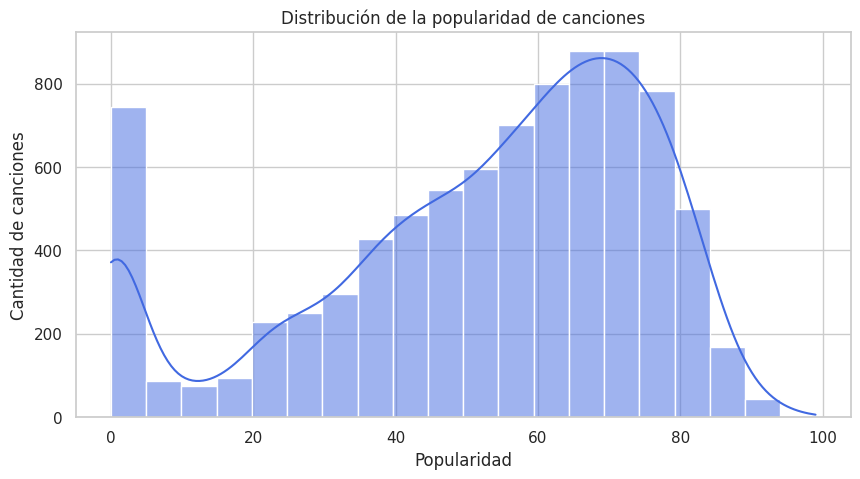

In [17]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x="track_popularity",
    bins=20,
    kde=True,
    color="royalblue"
)

plt.title("Distribución de la popularidad de canciones")
plt.xlabel("Popularidad")
plt.ylabel("Cantidad de canciones")

plt.show()

Relación entre popularidad de canciones y artistas

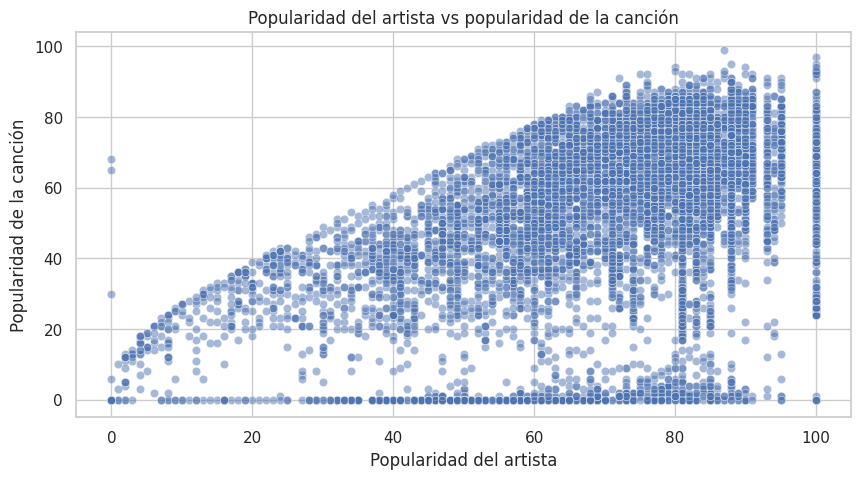

In [18]:
plt.figure(figsize=(10,5))

sns.scatterplot(
    data=df,
    x="artist_popularity",
    y="track_popularity",
    alpha=0.5
)

plt.title("Popularidad del artista vs popularidad de la canción")
plt.xlabel("Popularidad del artista")
plt.ylabel("Popularidad de la canción")

plt.show()

Relación entre seguidores y popularidad

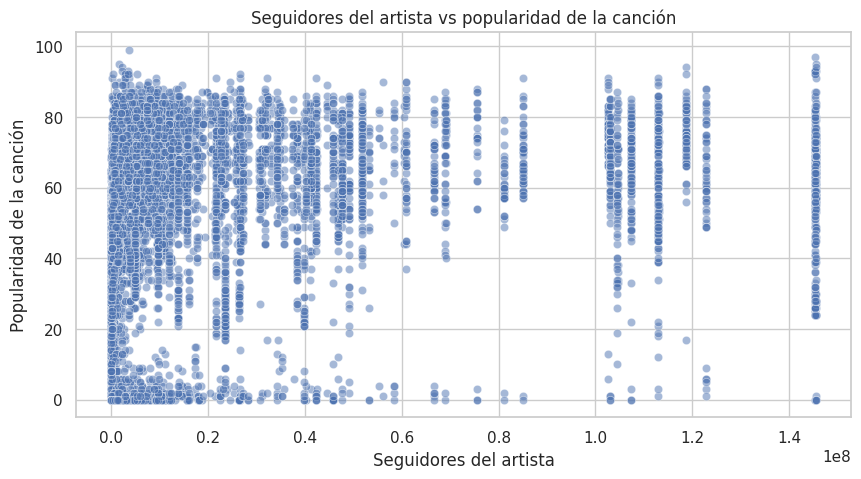

In [19]:
plt.figure(figsize=(10,5))

sns.scatterplot(
    data=df,
    x="artist_followers",
    y="track_popularity",
    alpha=0.5
)

plt.title("Seguidores del artista vs popularidad de la canción")
plt.xlabel("Seguidores del artista")
plt.ylabel("Popularidad de la canción")

plt.show()

Relación entre duración y popularidad

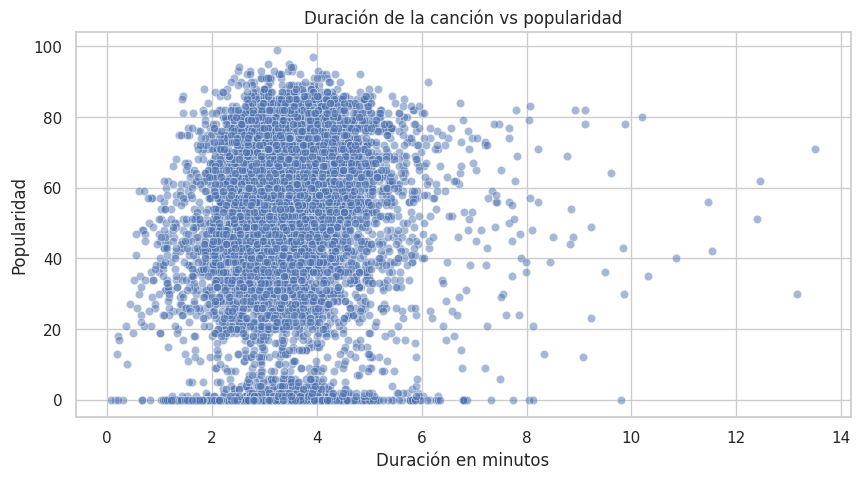

In [20]:
plt.figure(figsize=(10,5))

sns.scatterplot(
    data=df,
    x="track_duration_min",
    y="track_popularity",
    alpha=0.5
)

plt.title("Duración de la canción vs popularidad")
plt.xlabel("Duración en minutos")
plt.ylabel("Popularidad")

plt.show()

Matriz de correlación

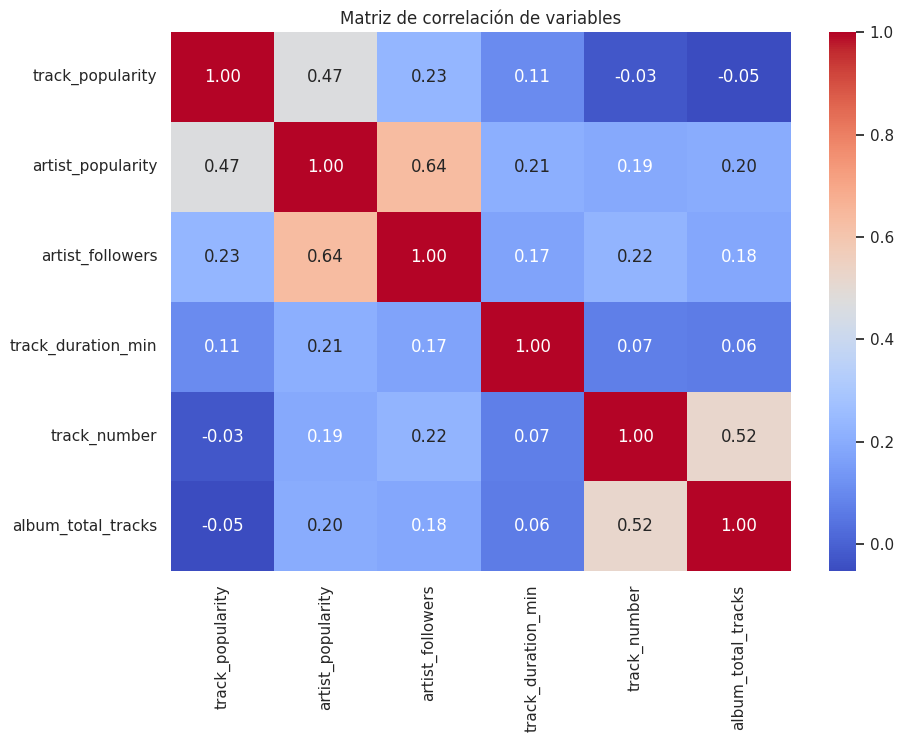

In [21]:
columnas_numericas = [
    "track_popularity",
    "artist_popularity",
    "artist_followers",
    "track_duration_min",
    "track_number",
    "album_total_tracks"
]

correlacion = df[columnas_numericas].corr()

plt.figure(figsize=(10,7))

sns.heatmap(
    correlacion,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de correlación de variables")

plt.show()

**Regresión lineal**

Queremos que el modelo aprenda de las características de las canciones para estimar qué puntuación de popularidad podrían tener.

Por ejemplo, si tenemos una canción con determinada duración, un artista con cierta popularidad y un número de seguidores, el modelo intentará estimar su popularidad en Spotify.

**Preparar los datos para la regresión lineal**

Nuestra variable objetivo será:

track_popularity

Primero crearemos la columna del año:



In [22]:
datos = df.copy()

datos["album_release_date"] = pd.to_datetime(
    datos["album_release_date"],
    errors="coerce"
)

datos["release_year"] = datos["album_release_date"].dt.year

Ahora seleccionamos las variables:

In [23]:
columnas = [
    "artist_popularity",
    "artist_followers",
    "track_duration_min",
    "track_number",
    "album_total_tracks",
    "explicit",
    "album_type",
    "release_year"
]

X_reg = datos[columnas]

y_reg = datos["track_popularity"]

Eliminamos únicamente las filas que no tengan nuestra variable objetivo

In [24]:
datos_reg = pd.concat([X_reg, y_reg], axis=1)

datos_reg = datos_reg.dropna(
    subset=["track_popularity"]
)

X_reg = datos_reg[columnas]
y_reg = datos_reg["track_popularity"]

Dividir los datos en entrenamiento y prueba

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (6865, 8)
Datos de prueba: (1717, 8)


Preparar las variables numéricas y categóricas

In [26]:
variables_numericas = [
    "artist_popularity",
    "artist_followers",
    "track_duration_min",
    "track_number",
    "album_total_tracks",
    "release_year"
]

variables_categoricas = [
    "explicit",
    "album_type"
]

# Pipeline para variables numéricas
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Pipeline para variables categóricas
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Unir los dos procesamientos
preprocessing = ColumnTransformer([
    ("num", num_pipeline, variables_numericas),
    ("cat", cat_pipeline, variables_categoricas)
])

**Entrenar el modelo de regresión lineal**

In [27]:
# Crear el modelo
modelo_regresion = Pipeline([
    ("preprocessing", preprocessing),
    ("regression", LinearRegression())
])

# Entrenar
modelo_regresion.fit(X_train, y_train)

# Realizar predicciones
predicciones_reg = modelo_regresion.predict(X_test)

print("Modelo de regresión entrenado correctamente")

Modelo de regresión entrenado correctamente


Evaluar el modelo de regresión lineal

In [28]:
mae = mean_absolute_error(
    y_test,
    predicciones_reg
)

rmse = np.sqrt(
    mean_squared_error(y_test, predicciones_reg)
)

r2 = r2_score(
    y_test,
    predicciones_reg
)

print("RESULTADOS DE REGRESIÓN LINEAL")

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²:", round(r2, 4))

RESULTADOS DE REGRESIÓN LINEAL
MAE: 15.71
RMSE: 20.68
R²: 0.2805


**Modelo de aprendizaje automático: árbol de decisión**

Crear las categorías de popularidad
Vamos a crear una nueva columna llamada categoria_popularidad.

Los rangos serán:

0 a 39	Baja

40 a 69	Media

70 a 100	Alta





In [29]:
datos_arbol = df.copy()

datos_arbol["categoria_popularidad"] = pd.cut(
    datos_arbol["track_popularity"],
    bins=[-1, 39, 69, 100],
    labels=["Baja", "Media", "Alta"]
)

print("Cantidad de canciones por categoría:")

print(
    datos_arbol["categoria_popularidad"].value_counts()
)

Cantidad de canciones por categoría:
categoria_popularidad
Media    4005
Alta     2373
Baja     2204
Name: count, dtype: int64


**Seleccionar las variables de entrada y salida**

Para este modelo utilizaremos las mismas variables que en la regresión lineal.
La diferencia es que ahora nuestra variable objetivo será categoria_popularidad.

In [30]:
# Crear una copia del dataset
datos_arbol = df.copy()

# Convertir la fecha de lanzamiento
datos_arbol["album_release_date"] = pd.to_datetime(
    datos_arbol["album_release_date"],
    errors="coerce"
)

# Extraer el año
datos_arbol["release_year"] = (
    datos_arbol["album_release_date"].dt.year
)

# Crear las categorías de popularidad
datos_arbol["categoria_popularidad"] = pd.cut(
    datos_arbol["track_popularity"],
    bins=[-1, 39, 69, 100],
    labels=["Baja", "Media", "Alta"]
)

print("Columnas creadas correctamente")
print(datos_arbol.columns.tolist())

Columnas creadas correctamente
['track_id', 'track_name', 'track_number', 'track_popularity', 'explicit', 'artist_name', 'artist_popularity', 'artist_followers', 'artist_genres', 'album_id', 'album_name', 'album_release_date', 'album_total_tracks', 'album_type', 'track_duration_min', 'release_year', 'categoria_popularidad']


In [31]:
# Variables de entrada
X_arbol = datos_arbol[columnas].copy()

# Variable objetivo
y_arbol = datos_arbol["categoria_popularidad"]

print("Variables para clasificar:")
print(X_arbol.columns.tolist())

print("\nVariable objetivo:")
print(y_arbol.name)

Variables para clasificar:
['artist_popularity', 'artist_followers', 'track_duration_min', 'track_number', 'album_total_tracks', 'explicit', 'album_type', 'release_year']

Variable objetivo:
categoria_popularidad


Dividir los datos en entrenamiento y prueba

In [32]:
X_train_arbol, X_test_arbol, y_train_arbol, y_test_arbol = train_test_split(
    X_arbol,
    y_arbol,
    test_size=0.20,
    random_state=42,
    stratify=y_arbol
)

print("Datos de entrenamiento:", X_train_arbol.shape)
print("Datos de prueba:", X_test_arbol.shape)

Datos de entrenamiento: (6865, 8)
Datos de prueba: (1717, 8)


Preparar y entrenar el árbol de decisión

In [33]:
# Crear el modelo de árbol de decisión
modelo_arbol = Pipeline([
    ("preprocessing", preprocessing),
    ("tree", DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=40,
        random_state=42
    ))
])

# Entrenar el modelo
modelo_arbol.fit(
    X_train_arbol,
    y_train_arbol
)

print("Árbol de decisión entrenado correctamente")

Árbol de decisión entrenado correctamente


Realizar predicciones y evaluar el árbol

In [34]:
# Realizar predicciones
predicciones_arbol = modelo_arbol.predict(X_test_arbol)

# Exactitud
accuracy = accuracy_score(
    y_test_arbol,
    predicciones_arbol
)

# Exactitud balanceada
balanced = balanced_accuracy_score(
    y_test_arbol,
    predicciones_arbol
)

print("RESULTADOS DEL ÁRBOL DE DECISIÓN")

print("Accuracy:", round(accuracy, 4))

print("Balanced Accuracy:", round(balanced, 4))

print("\nReporte de clasificación:")

print(
    classification_report(
        y_test_arbol,
        predicciones_arbol,
        zero_division=0
    )
)

RESULTADOS DEL ÁRBOL DE DECISIÓN
Accuracy: 0.5253
Balanced Accuracy: 0.5073

Reporte de clasificación:
              precision    recall  f1-score   support

        Alta       0.43      0.59      0.49       475
        Baja       0.73      0.34      0.47       441
       Media       0.55      0.59      0.57       801

    accuracy                           0.53      1717
   macro avg       0.57      0.51      0.51      1717
weighted avg       0.56      0.53      0.52      1717



**Visualizar el árbol de decisión**

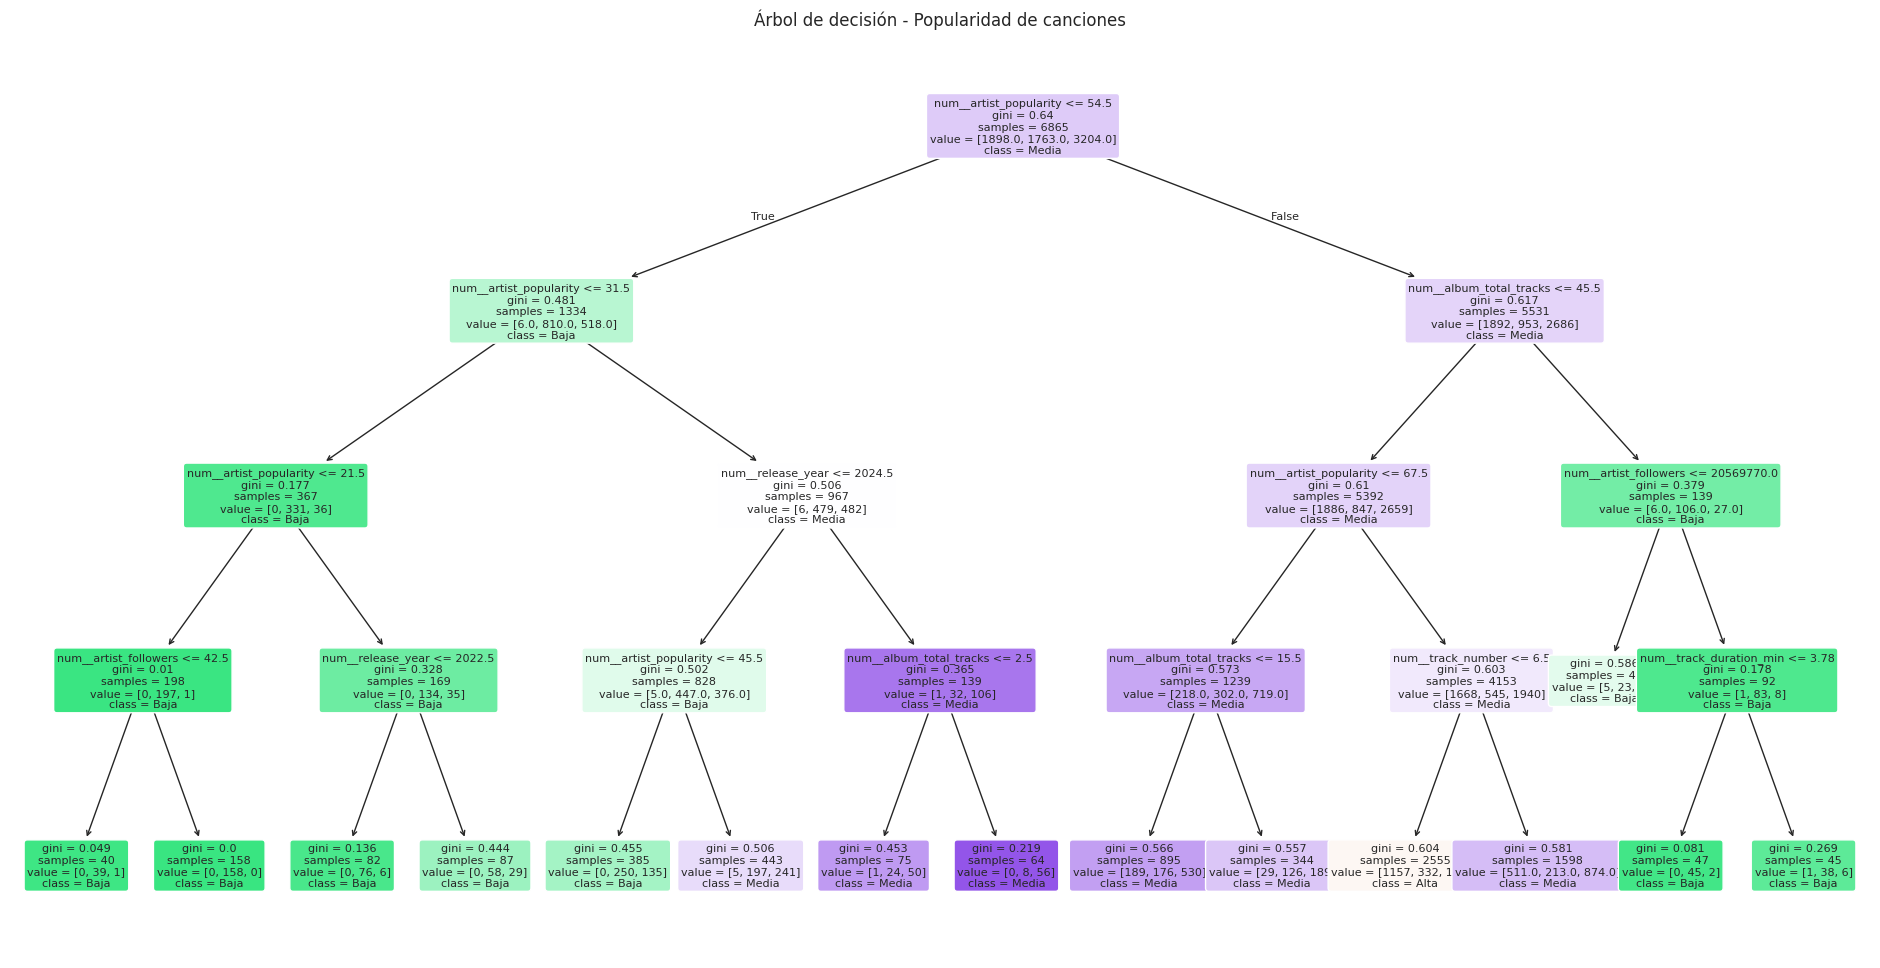

In [35]:
# Obtener el árbol entrenado
arbol = modelo_arbol.named_steps["tree"]

# Obtener los nombres de las variables procesadas
nombres_variables = (
    modelo_arbol
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

plt.figure(figsize=(24, 12))

plot_tree(
    arbol,
    feature_names=nombres_variables,
    class_names=list(arbol.classes_),
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Árbol de decisión - Popularidad de canciones")

plt.show()

**Matriz de confusión**

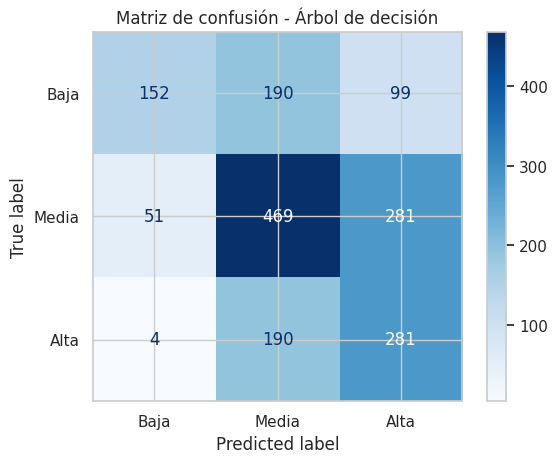

In [36]:
ConfusionMatrixDisplay.from_predictions(
    y_test_arbol,
    predicciones_arbol,
    labels=["Baja", "Media", "Alta"],
    cmap="Blues"
)

plt.title("Matriz de confusión - Árbol de decisión")

plt.show()

Importancia de las variables

Importancia de las variables:


,0
num__artist_popularity,0.7638
num__album_total_tracks,0.1308
num__track_number,0.0499
num__release_year,0.0418
num__artist_followers,0.0129
num__track_duration_min,0.0007
cat__explicit_False,0.0000
cat__explicit_True,0.0000
cat__album_type_album,0.0000
cat__album_type_compilation,0.0000


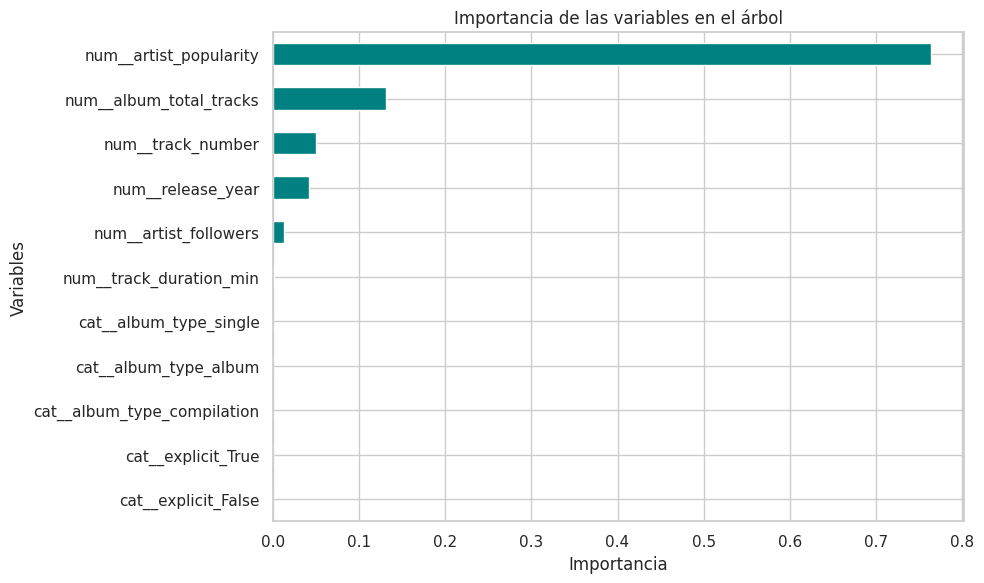

In [37]:
importancias = pd.Series(
    arbol.feature_importances_,
    index=nombres_variables
)

importancias = importancias.sort_values(
    ascending=False
)

print("Importancia de las variables:")

display(importancias.round(4))

plt.figure(figsize=(10,6))

importancias.sort_values().plot(
    kind="barh",
    color="teal"
)

plt.title("Importancia de las variables en el árbol")
plt.xlabel("Importancia")
plt.ylabel("Variables")

plt.tight_layout()
plt.show()

### **Modelo de Aprendizaje Automático: Random Forest (Bosque Aleatorio)**

Para mejorar los resultados obtenidos con el árbol de decisión individual, implementaremos un modelo de ensamble de **Random Forest (Clasificación)**. Este modelo combina múltiples árboles de decisión para realizar una predicción más robusta y generalizable.

In [38]:
from sklearn.ensemble import RandomForestClassifier

# Crear el pipeline con Random Forest
modelo_rf = Pipeline([
    ("preprocessing", preprocessing),
    ("rf", RandomForestClassifier(
        n_estimators=100,
        max_depth=6,
        min_samples_leaf=20,
        random_state=42,
        n_jobs=-1
    ))
])

# Entrenar el modelo de Random Forest
modelo_rf.fit(X_train_arbol, y_train_arbol)

# Realizar predicciones
predicciones_rf = modelo_rf.predict(X_test_arbol)

print("Random Forest entrenado correctamente")

Random Forest entrenado correctamente


#### **Evaluación del Random Forest**

In [39]:
# Exactitud
accuracy_rf = accuracy_score(
    y_test_arbol,
    predicciones_rf
)

# Exactitud balanceada
balanced_rf = balanced_accuracy_score(
    y_test_arbol,
    predicciones_rf
)

print("RESULTADOS DE RANDOM FOREST")
print("Accuracy:", round(accuracy_rf, 4))
print("Balanced Accuracy:", round(balanced_rf, 4))

print("\nReporte de clasificación:")
print(
    classification_report(
        y_test_arbol,
        predicciones_rf,
        zero_division=0
    )
)

RESULTADOS DE RANDOM FOREST
Accuracy: 0.5702
Balanced Accuracy: 0.4953

Reporte de clasificación:
              precision    recall  f1-score   support

        Alta       0.57      0.21      0.31       475
        Baja       0.78      0.39      0.52       441
       Media       0.53      0.88      0.67       801

    accuracy                           0.57      1717
   macro avg       0.63      0.50      0.50      1717
weighted avg       0.61      0.57      0.53      1717



#### **Matriz de Confusión para Random Forest**

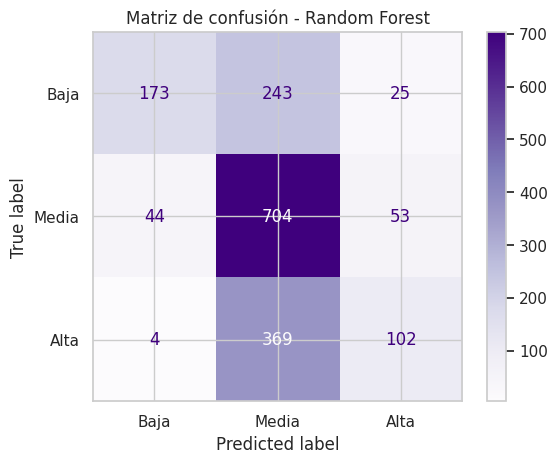

In [40]:
ConfusionMatrixDisplay.from_predictions(
    y_test_arbol,
    predicciones_rf,
    labels=["Baja", "Media", "Alta"],
    cmap="Purples"
)

plt.title("Matriz de confusión - Random Forest")
plt.show()

#### **Importancia de las variables en Random Forest**

Importancia de las variables (Random Forest):


,0
num__artist_popularity,0.4034
num__artist_followers,0.2673
num__album_total_tracks,0.1165
num__release_year,0.0584
num__track_duration_min,0.0491
num__track_number,0.0419
cat__album_type_album,0.0273
cat__album_type_compilation,0.0147
cat__album_type_single,0.0106
cat__explicit_True,0.0056


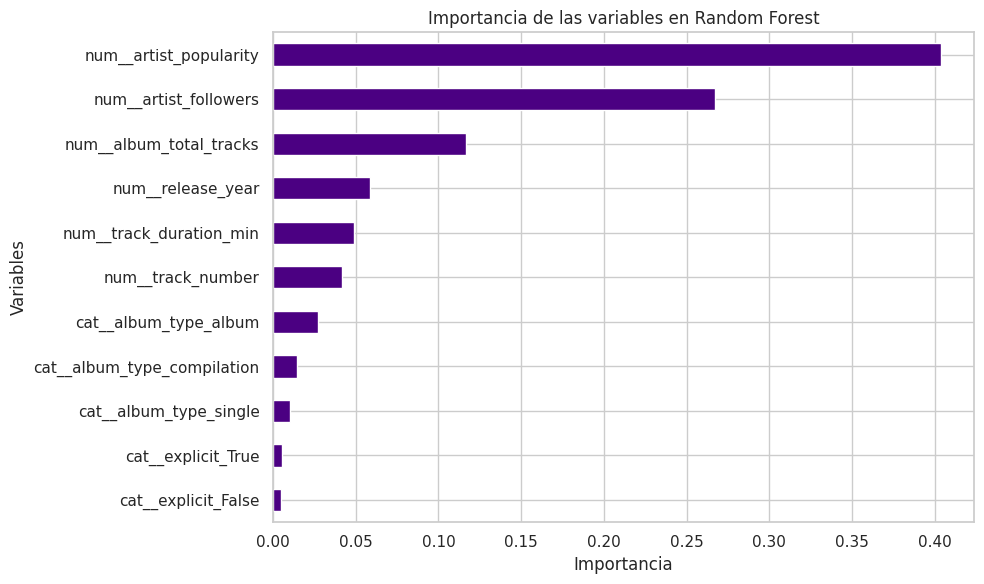

In [41]:
# Obtener el estimador del Random Forest
rf_estimator = modelo_rf.named_steps["rf"]

# Obtener importancias
importancias_rf = pd.Series(
    rf_estimator.feature_importances_,
    index=nombres_variables
).sort_values(ascending=False)

print("Importancia de las variables (Random Forest):")
display(importancias_rf.round(4))

# Gráfica de importancia
plt.figure(figsize=(10,6))
importancias_rf.sort_values().plot(
    kind="barh",
    color="indigo"
)

plt.title("Importancia de las variables en Random Forest")
plt.xlabel("Importancia")
plt.ylabel("Variables")
plt.tight_layout()
plt.show()

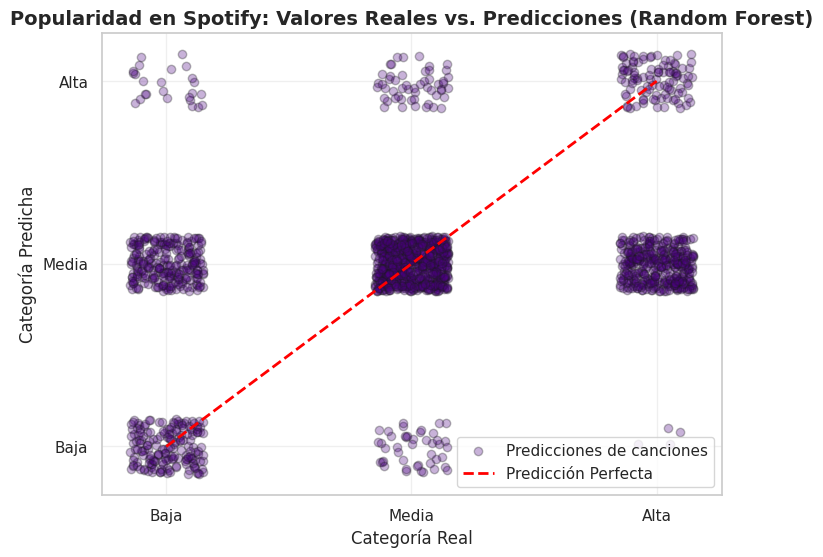

In [44]:


# Mapear las categorías a valores numéricos para graficar
mapeo_clases = {"Baja": 0, "Media": 1, "Alta": 2}
y_test_num = y_test_arbol.map(mapeo_clases).astype(float)
ypred_num = pd.Series(predicciones_rf).map(mapeo_clases).astype(float)

# Añadir un pequeño ruido (jitter) para que no se superpongan todos los puntos en las coordenadas exactas
random_generator = np.random.default_rng(42)
jitter_test = y_test_num + random_generator.uniform(-0.15, 0.15, size=len(y_test_num))
jitter_pred = ypred_num + random_generator.uniform(-0.15, 0.15, size=len(ypred_num))

plt.figure(figsize=(8, 6))

# Puntos reales vs predicciones con ligero jitter para mejorar visualización
plt.scatter(jitter_test, jitter_pred, alpha=0.3, color='indigo', edgecolor='k', label='Predicciones de canciones')

# Línea de predicción perfecta (y = x)
plt.plot([0, 2], [0, 2], color='red', linestyle='--', linewidth=2, label='Predicción Perfecta')

# Configuración de etiquetas de las clases
plt.xticks([0, 1, 2], ["Baja", "Media", "Alta"])
plt.yticks([0, 1, 2], ["Baja", "Media", "Alta"])

plt.title('Popularidad en Spotify: Valores Reales vs. Predicciones con Random Forest', fontsize=14, fontweight='bold')
plt.xlabel('Categoría Real', fontsize=12)
plt.ylabel('Categoría Predicha', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Conclusiones**

En esta práctica se realizó un análisis del conjunto de datos de canciones de Spotify utilizando dos algoritmos de aprendizaje automático: regresión lineal y árbol de decisión.

En primer lugar, mediante la regresión lineal se buscó predecir la popularidad de las canciones utilizando características como la popularidad del artista, el número de seguidores, la duración de las canciones y las características de sus álbumes.